# Phase 1 — Problem, Data & Exploration
### Multi-Task Visual Counting and Localization in Dense Scenes

**Course:** Deep Neural Networks for Data Analysis — Project (ed. 2026/2027)

**Goal:** Fine-tune a small single-head YOLO model on the **CARPK** dataset to **detect**,
**localize** and **count** cars in aerial parking-lot images.

Contents:

1. **Problem formulation**
2. **Technical review of existing solutions**
3. **Collected data & exploration**


---
## 1. Problem formulation

### 1.1 Precise problem statement
Given an **aerial (drone) RGB image** of a parking lot, the system must:

- **Detect** every car present (object detection),
- **Localize** each car with an axis-aligned **bounding box**, and
- **Count** the total number of cars in the image.

Formally, for an input image $I \in \mathbb{R}^{H\times W\times 3}$ the model outputs a set
of boxes $\{b_i = (x_i, y_i, w_i, h_i)\}_{i=1}^{N}$ for the single class *car*. After
Non-Maximum Suppression (NMS) the **count** is obtained by the *counting-by-detection* rule:

$$\widehat{\text{count}}(I) = \lvert \{b_i\}\rvert = \text{len(boxes after NMS)}.$$


### 1.2 Data source (real-world evidence)
Two real-world aerial parking-lot datasets are **combined into one dataset** (section 3.0):

- **CARPK** — drone images of 4 parking lots,
- **PUCPR+** — a fixed high camera over one parking lot.


### 1.3 Optimized metrics
- **Counting quality** — where
  $c_k$ is the ground-truth car count and $\hat c_k$ the predicted count:

$$\text{MAE}=\frac{1}{M}\sum_{k=1}^{M}\lvert \hat c_k - c_k\rvert,\qquad
\text{RMSE}=\sqrt{\frac{1}{M}\sum_{k=1}^{M}(\hat c_k - c_k)^2}.$$

- **Detection quality** — mean Average Precision at IoU 0.5, **mAP@0.5**, (plus mAP@0.5:0.95
  as a secondary indicator) to confirm boxes are well localized, not just counted correctly.


---
## 2. Technical review of existing solutions

### 2.1 Zero-shot reference: the un-fine-tuned YOLO baseline
Before any training we benchmark the **exact base model we will fine-tune** — COCO-pretrained **YOLO11n**, counting only its COCO `car` class.

In [1]:
import sys; sys.path.insert(0, "src/1_phase")
import baseline

model = baseline.load_model("models/yolo11n.pt")
test_ids = baseline.load_test_ids()

zs = baseline.run_zeroshot_baseline(model, test_ids)
zs["result"]

,Model,mean GT,mean pred,MAE,RMSE
0,"YOLO11n zero-shot (COCO-pretrained, no fine-tu...",106.2,7.6,98.67,111.12


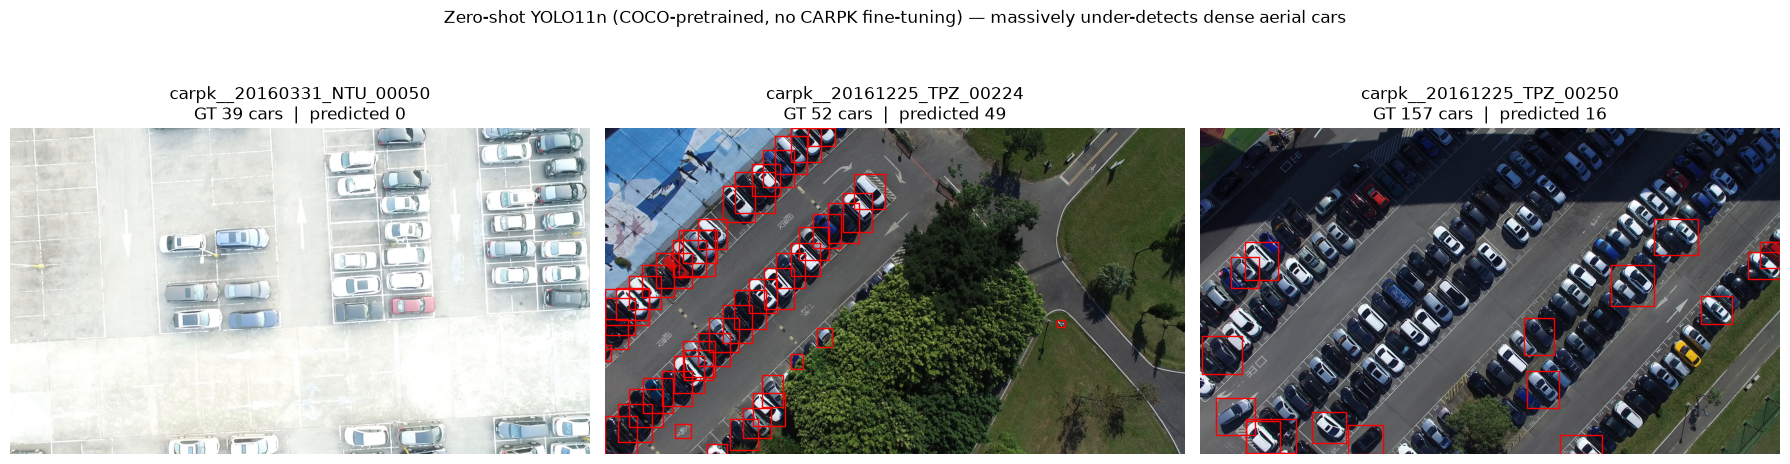

In [2]:
baseline.plot_zeroshot_examples(model)

### 2.2 Typical detectors for dense small objects
- **YOLO family (YOLO11/12/26):** single-stage, real-time, clean single detection head;
  strong on small objects at high input resolution. Chosen here (YOLO11n) for speed.
- **Faster R-CNN:** two-stage, accurate but slower/heavier — the classic CARPK baseline.
- **RetinaNet / FCOS:** one-stage focal-loss / anchor-free heads with good small-object recall.

For hundreds of tiny, tightly packed cars, **input resolution** and **NMS behaviour** matter
more than backbone size — hence training at `imgsz=1280` with a small backbone.

### 2.3 Counting-by-detection vs density-map counting
- **Density-map counting** regresses a per-pixel density map whose integral is the count
  (e.g. MCNN, CSRNet). It excels at extreme crowding/occlusion but gives **no boxes**, so it
  cannot localize individual cars.
- **Counting-by-detection** detects each object and sets `count = #boxes`. It yields both
  **localization and count** in one pass, and is directly interpretable.

**Justification:** the project deliverable is an app that returns an **image with boxed cars
+ total count**. Localization is therefore mandatory, so counting-by-detection is the natural
choice; CARPK cars are large and separated enough for a detector to resolve them individually.

### 2.4 Typical training approach
- **Transfer learning:** start from COCO-pretrained weights and fine-tune on CARPK — far
  fewer epochs and better small-object features than training from scratch.
- **High input resolution** (`imgsz=1280`, native size) so small cars survive downsampling.
- **Augmentation:** mosaic, scale/translate jitter, HSV; **single class** `0 = car`.
- **Multi-GPU** data-parallel training (`device=[0,1]`) to halve wall-clock time.

---
## 3. Collected data & exploration

### 3.0 Combining the datasets into one final dataset
Two complementary aerial car devkits ship with this project and share the **exact same**
on-disk layout and annotation format (`x1 y1 x2 y2 class`, absolute pixels, class `1 = car`,
native 1280x720):

- **CARPK** — 1448 drone images over 4 parking lots (`datasets/CARPK_devkit`),
- **PUCPR+** — 125 fixed-camera parking-lot images in varied weather (`datasets/PUCPR+_devkit`).



In [3]:
import sys; sys.path.insert(0, "src/1_phase")
import combine

combined_summary = combine.combine_datasets()
combined_summary

  pucpr: dropped 55 degenerate boxes (zero width/height)
Final combined devkit written to: datasets/combined_devkit/data
  train: 1089 images / 55215 cars
  test : 484 images / 51420 cars


,source,split,images,cars
0,carpk,train,989,42274
1,carpk,test,459,47500
2,pucpr,train,100,12941
3,pucpr,test,25,3920


In [4]:
import exploration

train_ids, test_ids, all_ids = exploration.load_splits()

#images total: 1573 | #train: 1089 | #test: 484


In [5]:
exploration.check_sample_resolution(all_ids)

Sample image: carpk__20160331_NTU_00001 size (1280, 720)


(1280, 720)

In [6]:
boxes, per_image_counts, degenerate = exploration.parse_annotations(all_ids, train_ids)
boxes.head()

Total annotated cars: 106,635 | classes: [np.int64(1)]


,img_id,split,x1,y1,x2,y2,cls,w,h,area,aspect
0,carpk__20160331_NTU_00001,train,1019,521,1129,571,1,110,50,5500,2.200000
1,carpk__20160331_NTU_00001,train,1013,583,1120,634,1,107,51,5457,2.098039
2,carpk__20160331_NTU_00001,train,1007,640,1112,693,1,105,53,5565,1.981132
3,carpk__20160331_NTU_00001,train,1006,694,1119,719,1,113,25,2825,4.520000
4,carpk__20160331_NTU_00002,train,1023,524,1131,570,1,108,46,4968,2.347826


In [7]:
print(f"Degenerate boxes still present after parsing: {len(degenerate)}")
assert len(degenerate) == 0, "degenerate boxes leaked into the combined devkit"
print("OK — combined devkit has no zero width/height boxes.")

Degenerate boxes still present after parsing: 0
OK — combined devkit has no zero width/height boxes.


In [8]:
exploration.cars_per_image_summary(per_image_counts, train_ids, test_ids)

,images,total_cars,min,max,mean,median,std
all,1573.0,106635.0,0.0,331.0,67.79,50.0,52.24
train,1089.0,55215.0,0.0,331.0,50.70,40.0,43.89
test,484.0,51420.0,1.0,328.0,106.24,112.0,49.04


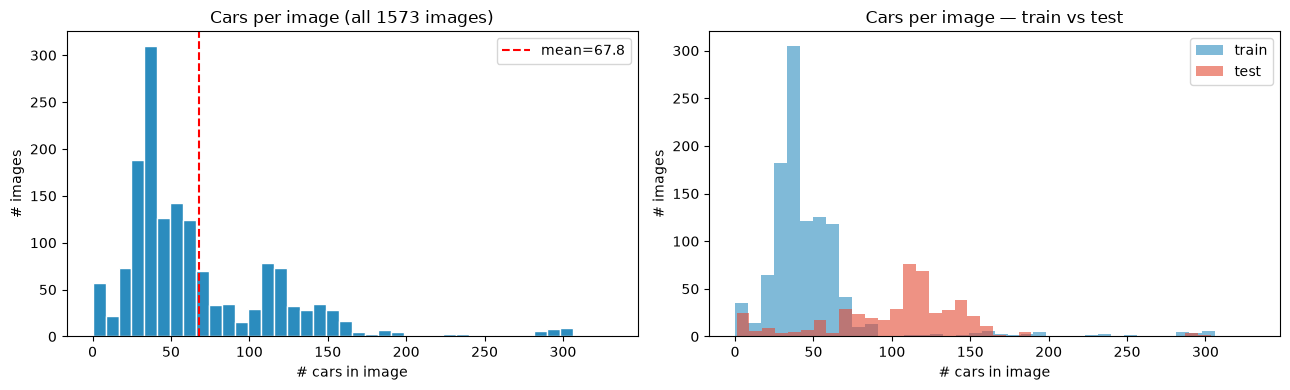

In [9]:
exploration.plot_cars_per_image(per_image_counts, train_ids, test_ids)

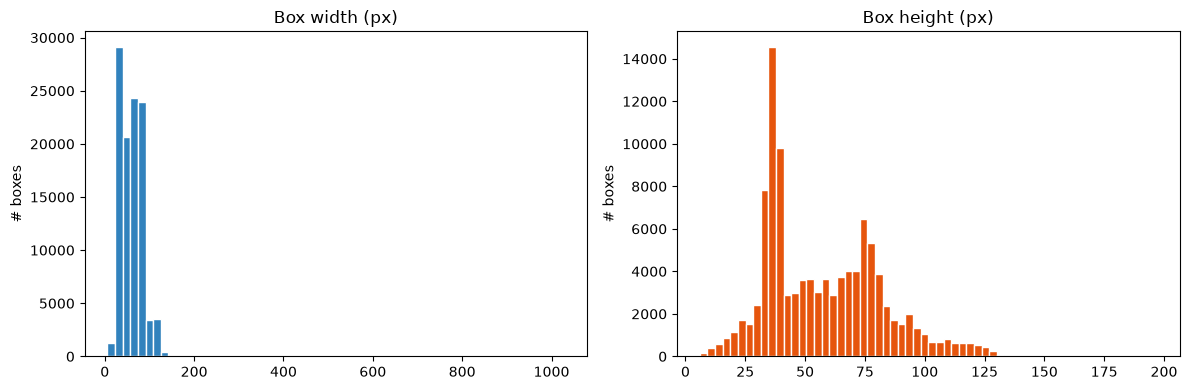

In [10]:
exploration.plot_box_wh(boxes)

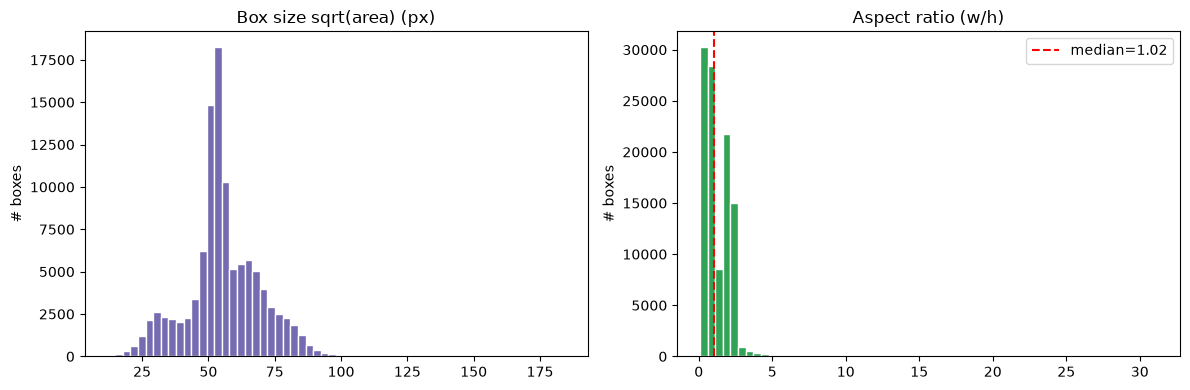

In [11]:
exploration.plot_box_sizes(boxes)

**Aspect ratio outliers.** Boxes with w/h > 3 are cars cut off at the image border (a few pixels tall at `y2 = 719`), not annotation errors:

- w/h > 3: **1,897 (2.1%)**
- w/h > 5: 562 (0.6%)
- w/h > 8: 83 (0.09%)
- w/h > 10: only **15 (0.017%)**

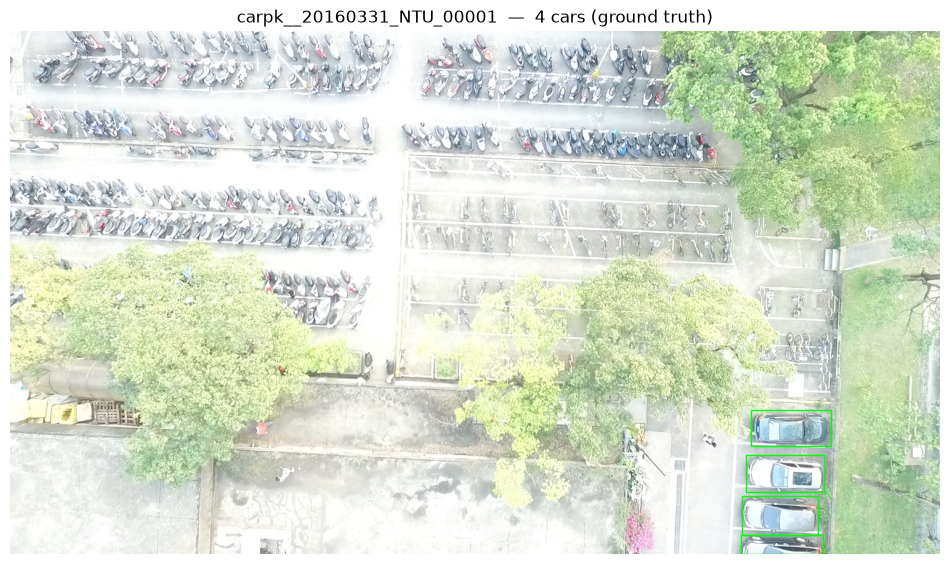

In [12]:
exploration.plot_sample_gt(boxes, train_ids)

### 3.1 Labeling format

**On-disk CARPK format** — one `.txt` per image in `Annotations/`, one line per car:

```
x1 y1 x2 y2 class
```

- `x1 y1` = top-left corner, `x2 y2` = bottom-right corner, **absolute pixels**;
- `class` = `1` (car) for every box (single-category dataset).

**Example:** `1019 521 1129 571 1` → a car box from (1019, 521) to (1129, 571).

**Target YOLO format** (conversion done in Phase 2) — normalized, single class `0 = car`:

$$c_x=\frac{x_1+x_2}{2W},\quad c_y=\frac{y_1+y_2}{2H},\quad
w=\frac{x_2-x_1}{W},\quad h=\frac{y_2-y_1}{H},$$

with $W=1280,\ H=720$, giving lines `0 cx cy w h` with all values in $[0,1]$.


In [13]:
exploration.conversion_demo(boxes)

CARPK : 1019 521 1129 571 1
YOLO  : 0 0.839063 0.758333 0.085938 0.069444


(np.float64(0.8390625),
 np.float64(0.7583333333333333),
 np.float64(0.0859375),
 np.float64(0.06944444444444445))

### 3.2 Train / val / test partition plan

| Split | Source | #images | Purpose |
|---|---|---|---|
| **train** | ~90% of official `train.txt` | ≈980 | fit model weights |
| **val**   | ~10% of official `train.txt` (random seed, held out) | ≈109 | model selection / early stopping |
| **test**  | official `test.txt` (untouched) | 484 | final MAE / RMSE / mAP benchmark |


In [14]:
exploration.train_val_partition(train_ids, test_ids, per_image_counts)

,split,#images,#cars,source
0,train (fit),980,49504,official train (90%)
1,val,109,5711,official train (10%)
2,test,484,51420,official test (clean)
